# PROBLEMA 5:

Nesse projeto, devo construir **um modelo de agrupamento k-means para poder identificar perfis de consumo de clientes** de um distribuidor atacadista.

#  Coisas que devo fazer no Dataset

1. Preparação dos dados: carregue o dataset e separe Channel e Region do restante. Para cada uma das seis categorias de gasto, calcule média, mediana, desvio padrão e valores extremos, e construa um boxplot ou histograma. Você observará distribuições fortemente assimétricas à direita, com poucos clientes de gasto muito elevado — em Fresh, por exemplo, os valores vão de dezenas a mais de cem mil unidades monetárias.
Aplique então a transformação logarı́tmica 𝑥 ′ = log(1 + 𝑥) e, em seguida, padronize os atributos por 𝑍-score.Justifique as duas etapas separadamente: (a) por que a transformação logarı́tmica é recomendável diante da assimetria e da presença de outliers, e (b) por que a padronização é determinante para o 𝑘-Means, relacionando sua resposta ao uso da distância euclidiana na atribuição dos pontos aos centróides. Calcule também a matriz de correlação entre as seis categorias e comente o par Grocery–Detergents Paper.

2. Ausência de divisão treino/teste: diferentemente dos projetos anteriores, aqui não se separa um conjunto de teste. Explique por quê, contrastando o objetivo do aprendizado supervisionado (estimar o erro de generalização sobre rótulos conhecidos) com o do não supervisionado. Discuta, então, qual é a dificuldade central da validação em agrupamento: como afirmar que uma partição é “boa” sem dispor de um gabarito?

3. Escolha do número de grupos: execute o 𝑘-Means para 𝑘 variando de 2 a 10. Plote a inércia (soma dos quadrados intra-cluster) em função de 𝑘 e aplique o método do cotovelo; em seguida, plote o coeficiente de silhueta médio em função de 𝑘. Escolha o valor de 𝑘 justificando sua decisão à luz dos dois critérios e da interpretabilidade comercial dos grupos resultantes — um segmento só é útil se a área comercial souber o que fazer com ele. 

Responda: por que a inércia decresce monotonicamente com 𝑘 e por que, portanto, ela não pode ser usada isoladamente como critério de escolha? O que ocorre no caso limite em que 𝑘 é igual ao número de amostras?

4. Inicialização e convergência: o 𝑘-Means converge para um mı́nimo local, e não necessariamente global. Execute o algoritmo dez vezes com init=’random’ e n init=1, usando sementes distintas, e registre a inércia final de cada execução. Repita o procedimento com init=’k-means++’. Compare a dispersão dos resultados nos dois casos e explique qual problema a inicialização k-means++ busca mitigar e de que forma.

5. Interpretação e validação dos grupos: com o 𝑘 escolhido, recupere os centróides, reverta-os para a escala original de gasto (desfazendo a padronização e a transformação logarı́tmica) e apresente-os em uma tabela e em um gráfico de barras agrupadas por categoria. Atribua a cada agrupamento um nome descritivo de natureza comercial, baseado nas categorias em que ele se destaca. Em seguida, realize uma validação externa: construa tabelas de contingência cruzando o agrupamento de cada cliente com Channel e com Region, e calcule o ı́ndice Rand ajustado (Adjusted Rand Index) entre a partição obtida e a variável Channel. 

Responda: o algoritmo, sem jamais ter visto o canal de venda, foi capaz de reconstruı́-lo? Qual conjunto de categorias de produto mais separa Horeca de Retail? E a região geográfica — ela se reflete nos agrupamentos? Por fim, projete os dados em duas dimensões por PCA, colorindo os pontos por agrupamento, e discuta duas limitações do 𝑘-Means evidenciadas nesse gráfico: a tendência a formar grupos de geometria esférica e de tamanhos semelhantes e a sensibilidade a outliers.

---

**Observação**: os atributos Channel e Region não devem ser utilizados no agrupamento. Eles serão reservados para a validação externa da tarefa 5. O agrupamento deve basear-se exclusivamente nas seis categorias de gasto.

In [17]:
# importando as  bibliotecas inicias

import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

In [18]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
wholesale_customers = fetch_ucirepo(id=292) 
  
# separando features e target
X = wholesale_customers.data.features 
y = wholesale_customers.data.targets 
  
# juntando as colunas de features + target
df = pd.concat([X,y], axis= 1)

df.head()

,Channel,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Region
0,2,12669,9656,7561,214,2674,1338,3
1,2,7057,9810,9568,1762,3293,1776,3
2,2,6353,8808,7684,2405,3516,7844,3
3,1,13265,1196,4221,6404,507,1788,3
4,2,22615,5410,7198,3915,1777,5185,3


## 1. Preparação dos dados: carregue o dataset e separe Channel e Region do restante. Para cada uma das seis categorias de gasto, calcule média, mediana, desvio padrão e valores extremos, e construa um boxplot ou histograma. Você observará distribuições fortemente assimétricas à direita, com poucos clientes de gasto muito elevado — em Fresh, por exemplo, os valores vão de dezenas a mais de cem mil unidades monetárias. Aplique então a transformação logarı́tmica 𝑥 ′ = log(1 + 𝑥) e, em seguida, padronize os atributos por 𝑍-score.Justifique as duas etapas separadamente: (a) por que a transformação logarı́tmica é recomendável diante da assimetria e da presença de outliers, e (b) por que a padronização é determinante para o 𝑘-Means, relacionando sua resposta ao uso da distância euclidiana na atribuição dos pontos aos centróides. Calcule também a matriz de correlação entre as seis categorias e comente o par Grocery–Detergents Paper.

Com o dataset anteriormente carregado, agora serão separadas as variáveis para validação externa. Logo após isso, sobrarão apenas as features de categorias de gasto. Para cada uma das 6 categorias de gasto, foram calculados:

- media
- mediana
- desvio padrão 
- valores extremos (min e max)

In [19]:
# separando as variáveis channel e region do restante
info_cols = ['Channel','Region']
gastos_cols = ['Fresh','Milk','Grocery','Frozen','Detergents_Paper','Delicassen']

# att o dataset
df_info = df[info_cols]
df_gastos = df[gastos_cols]

# tabela das métricas estatísticas
estatisticas = pd.DataFrame({
    'Média': df_gastos.mean(),
    'Mediana': df_gastos.median(),
    'Desvio Padrão': df_gastos.std(),
    'Mínimo': df_gastos.min(),
    'Máximo': df_gastos.max(),
    'Assimetria (Skewness)':df_gastos.skew()
})


print("--- Estatísticas Descritivas das Categorias de Gastos (Escala Original) ---")
display(estatisticas.round(2))


--- Estatísticas Descritivas das Categorias de Gastos (Escala Original) ---


,Media,Mediana,Desvio Padrão,Mínimo,Máximo,Assimetria (Skewness)
Fresh,12000.30,8504.0,12647.33,3,112151,2.56
Milk,5796.27,3627.0,7380.38,55,73498,4.05
Grocery,7951.28,4755.5,9503.16,3,92780,3.59
Frozen,3071.93,1526.0,4854.67,25,60869,5.91
Detergents_Paper,2881.49,816.5,4767.85,3,40827,3.63
Delicassen,1524.87,965.5,2820.11,3,47943,11.15


Podemos observar inicialmente por meio do dataframe que ilustra as estatísticas descritivas das categorias de gastos que todas as variáveis possuem assimetria. Principalmente algumas em específico como `Delicassen`, `Frozen` e `Milk` possuem uma taxa de assimetria muito alta. 


---

Sabemos que existem 3 casos referentes à simetria:

1. Distribuição Simétrica: Quando a moda, mediana e média possuem valores iguais. O lado esquerdo = lado direito (quartis e percentis iguais).
2. Distribuição Assimétrica para Direita (positiva): moda < mediana < média
3. Distribuição Assimétrica para Esquerda (negativa): média < mediana < moda

Nesse caso, já é possível visualizar que ocorre a distribuição de forma assimétrica para a direita, pois em todas as features da tabela das estatísticas descritivas: mediana < média.

Isso será constatado com mais certeza quando conferirmos os boxplots e os histogramas das amostras


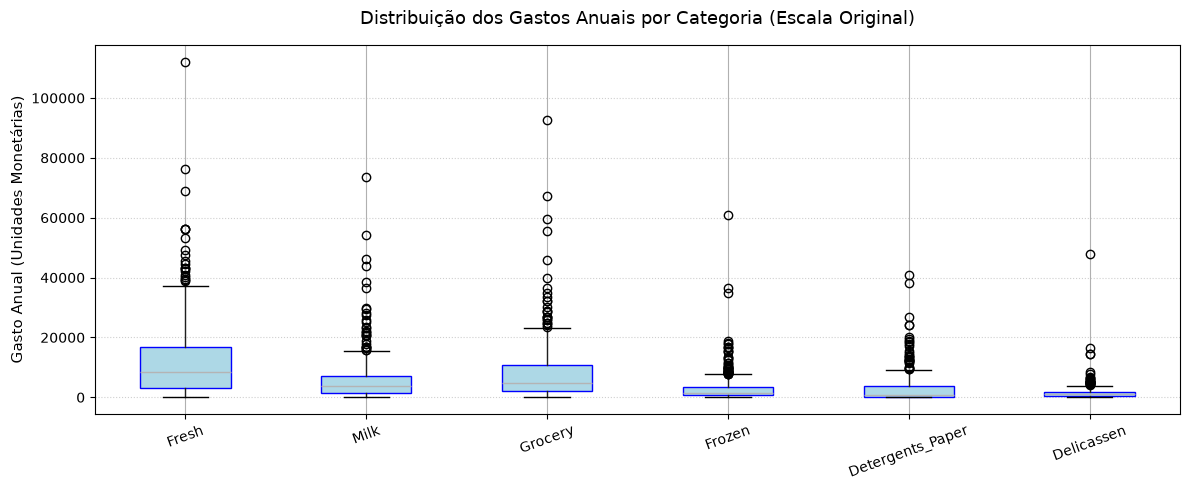

In [20]:
# visualizando a assimetria pelo boxplot 
plt.figure(figsize=(12, 5))
df_gastos.boxplot(patch_artist=True, boxprops=dict(facecolor='lightblue', color='blue'))
plt.title('Distribuição dos Gastos Anuais por Categoria (Escala Original)', fontsize=13, pad=15)
plt.ylabel('Gasto Anual (Unidades Monetárias)', fontsize=11)
plt.xticks(rotation=20, fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

É possível observar o caso de assimetria para a direita das features plotando os boxplots, basta apenas observar que além de predominar os valores mais altos das observações das amostras, os bigodes dos boxplots são mais alongados para cima, sinalizando assim uma assimetria positiva (ou para a direita). 

/tmp/ipykernel_4985/1460021231.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=9)


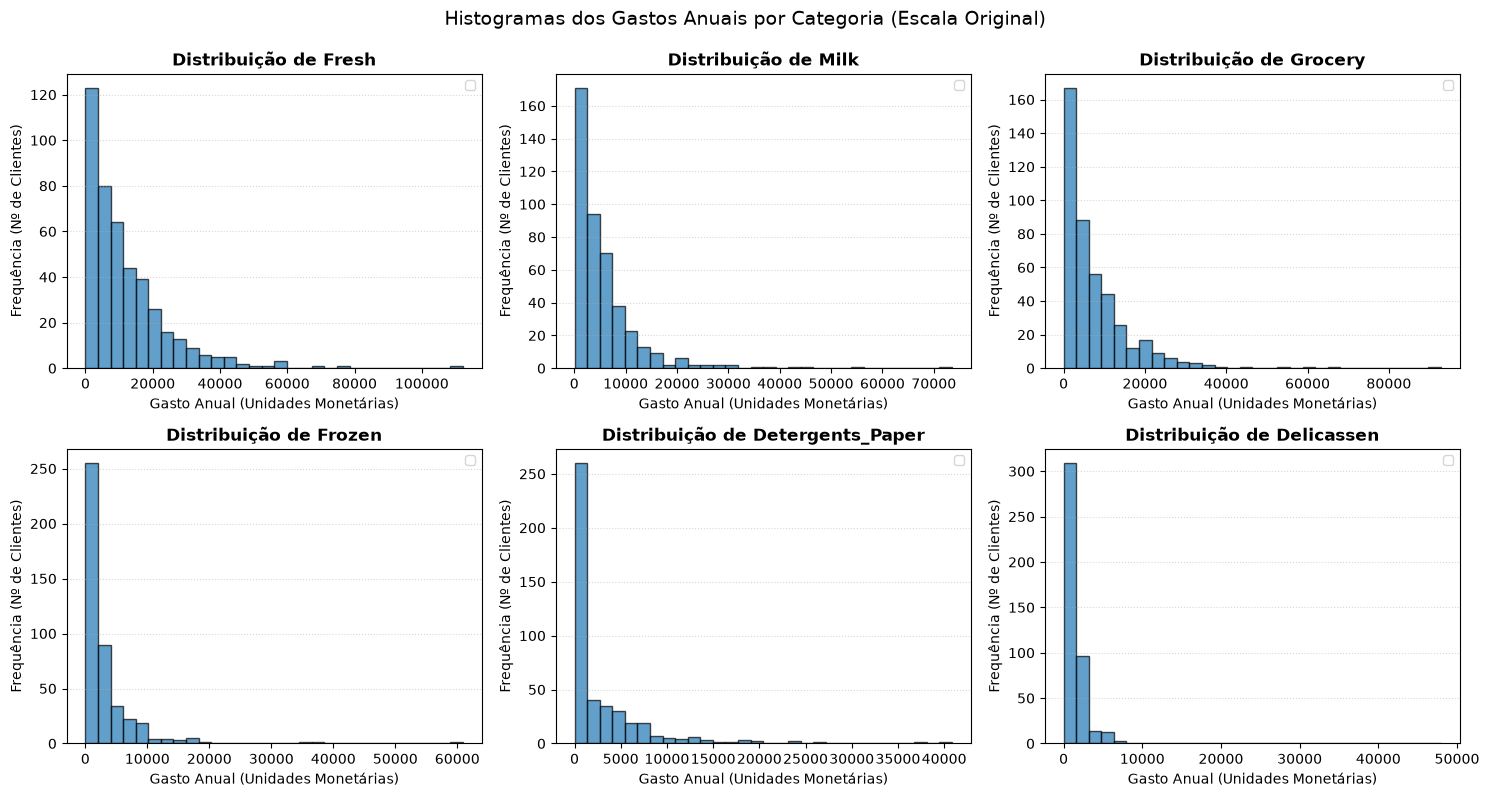

In [21]:
# visualizando a distribuição e assimetria por meio de histogramas (escala original)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(gastos_cols):
    ax = axes[i]
    # plotando o histograma com 30 bins
    ax.hist(df_gastos[col], bins=30, color='#1f77b4', edgecolor='black', alpha=0.7)
       
    ax.set_title(f'Distribuição de {col}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Gasto Anual (Unidades Monetárias)', fontsize=10)
    ax.set_ylabel('Frequência (Nº de Clientes)', fontsize=10)
    ax.grid(axis='y', linestyle=':', alpha=0.5)

plt.suptitle('Histogramas dos Gastos Anuais por Categoria (Escala Original)', fontsize=14, y=0.99)
plt.tight_layout()
plt.show()


A melhor forma de visualizar a assimetria para a direita das features é por meio do histograma, pois é a partir dele que podemos detectar que a "cauda" do histograma se alonga para o lado direito. Caracterizando assim o caso de assimetria para a direita. 

---

- **Aplicando a transformação logarítmica $x'=\log(1 + x)$**

Como foi visto anteriormente nos histogramas e boxplots, as features que representam os gastos anuais são fortemente assimétricas à direita, com uma presença massiva de outliers. A grande massa dos 440 clientes que a questão menciona gasta com valores modestos, contudo, existem alguns clientes que gastam mais de 100.000 na categoria de gasto `Fresh` ou mais de 90.000 na categoria de gasto `Grocery`.

Nesse sentido, pelo fato da função logarítmica ser uma função estritamente côncava, ela possui uma taxa de crescimento desacelerada. Isso significa que quando comparamos a diferença de gastos lineares: de 10 pra 100 em escala linear é 90, quando a diferença entre um gasto aumenta de 10.000 para 100.000 percebemos que fica 1.000 vezes maior.

Para contornarmos isso, aplicamos o log natural $\ln$): $$\ln(100) - \ln(10) \approx 4,60 - 2,30 = \mathbf{2,30}$$ $$\ln(100.000) - \ln(10.000) \approx 11,51 - 9,21 = \mathbf{2,30}$$

Perceba que o logaritmo acaba **comprimindo as ordens de grandeza astronômicas e expande as variações relativas menores**, puxando os clientes extremos (outliers) para perto da média e transforma as caudas longas que vimos no histograma em uma distribuição mais simétrica. Vale dizer que caso o cliente tenha gasto = 0, o log(x) = log(0) é indefinido, logo, é por isso que será utilizado o log(1+x).


- **Aplicando o Z-Score por meio do `StandardScaler` do sk-learn**

Como o algoritmo do k-means funciona agrupando cada cliente a um centróide mais próximo utilizando como métrica de distância padrão a distância euclidiana, pelo fato das features apresentarem escalas diferentes (algumas bem maiores do que as outras), as features com maiores amplitudes e dispersão (como `Fresh`) iriam produzir diferenças quadráticas durante o cálculo da distância na casa dos milhões. Já uma feature com amplitude menor (como `Delicassen`) iria produzir diferenças quadráticas menores, na casa das centenas.

É justamente por isso que faz necessário o uso do Z-Score, pois dessa forma, **as escalas das features são padronizadas e evitamos de variáveis com escalas significativamente maiores engolirem as escalas menores**.


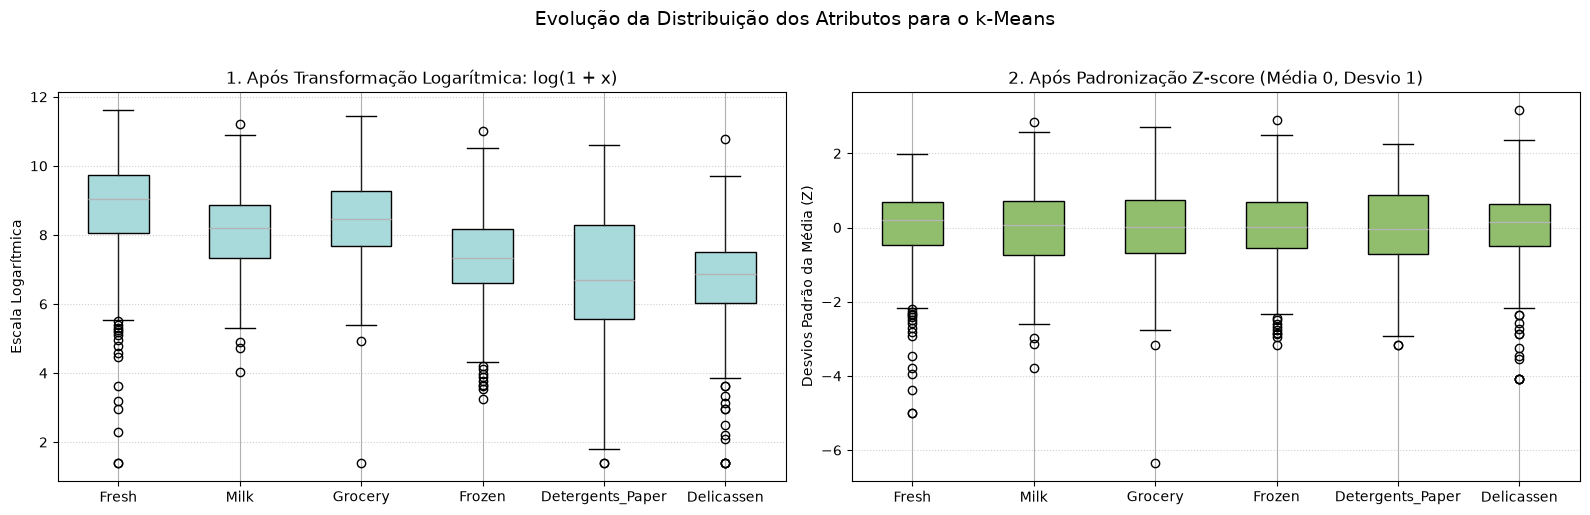

In [22]:
from sklearn.preprocessing import StandardScaler

# transformação logarítmica: x' = log(1 + x)
df_log = np.log1p(df_gastos)

# normalização por Z-score (média zero e desvio padrão unitário)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_log)

# df's auxiliares para visualização
df_scaled = pd.DataFrame(X_scaled, columns=gastos_cols)

# plotando o pré-processamento (antes vs depois)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

df_log.boxplot(ax=axes[0], patch_artist=True, boxprops=dict(facecolor='#a8dadc'))
axes[0].set_title("1. Após Transformação Logarítmica: log(1 + x)", fontsize=12)
axes[0].set_ylabel("Escala Logarítmica", fontsize=10)
axes[0].grid(axis='y', linestyle=':', alpha=0.6)

df_scaled.boxplot(ax=axes[1], patch_artist=True, boxprops=dict(facecolor='#90be6d'))
axes[1].set_title("2. Após Padronização Z-score (Média 0, Desvio 1)", fontsize=12)
axes[1].set_ylabel("Desvios Padrão da Média (Z)", fontsize=10)
axes[1].grid(axis='y', linestyle=':', alpha=0.6)

plt.suptitle("Evolução da Distribuição dos Atributos para o k-Means", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

- **Matriz de Correlação entre as seis categorias**

--- Matriz de Correlação Linear (Pearson) ---


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Fresh,1.0000,0.1005,-0.0119,0.3459,-0.1020,0.2447
Milk,0.1005,1.0000,0.7283,0.1240,0.6618,0.4064
Grocery,-0.0119,0.7283,1.0000,-0.0402,0.9246,0.2055
Frozen,0.3459,0.1240,-0.0402,1.0000,-0.1315,0.3909
Detergents_Paper,-0.1020,0.6618,0.9246,-0.1315,1.0000,0.0693
Delicassen,0.2447,0.4064,0.2055,0.3909,0.0693,1.0000


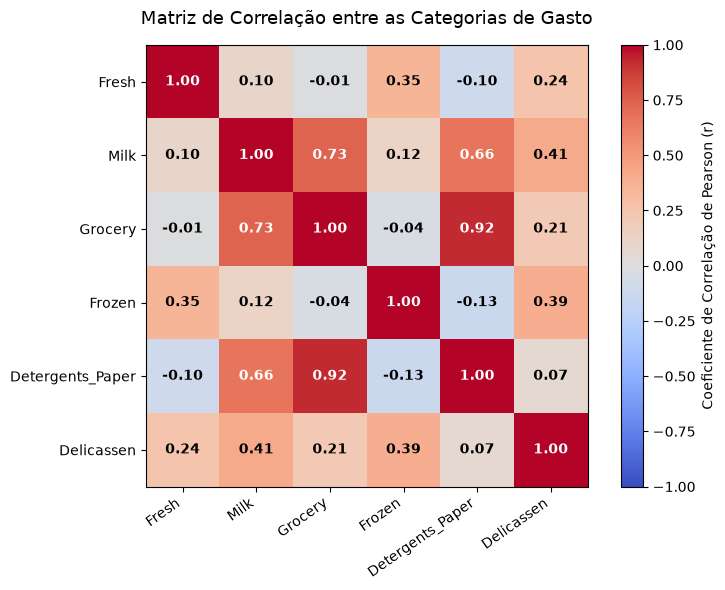


Correlação linear entre Grocery e Detergents_Paper: 0.9246 (92.46%)


In [23]:
# calculando a matriz de correlação de Pearson entre as 6 categorias de gastos
matriz_corr = df_gastos.corr()

print("--- Matriz de Correlação Linear (Pearson) ---")
display(matriz_corr.round(4))

# plotando o heatmap da matriz de correlação
plt.figure(figsize=(8, 6))
plt.imshow(matriz_corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Coeficiente de Correlação de Pearson (r)')

# adicionando os rótulos nos eixos
plt.xticks(range(len(gastos_cols)), gastos_cols, rotation=35, ha='right', fontsize=10)
plt.yticks(range(len(gastos_cols)), gastos_cols, fontsize=10)

# inserindo os valores numéricos em cada célula
for i in range(len(gastos_cols)):
    for j in range(len(gastos_cols)):
        valor = matriz_corr.iloc[i, j]
        cor_texto = "white" if abs(valor) > 0.55 else "black"
        plt.text(j, i, f"{valor:.2f}", ha='center', va='center', color=cor_texto, fontweight='bold', fontsize=10)

plt.title("Matriz de Correlação entre as Categorias de Gasto", fontsize=13, pad=15)
plt.tight_layout()
plt.show()

# exibindo a correlação específica do par pedido no enunciado
corr_g_dp = matriz_corr.loc['Grocery', 'Detergents_Paper']
print(f"\nCorrelação linear entre Grocery e Detergents_Paper: {corr_g_dp:.4f} ({corr_g_dp*100:.2f}%)")

O papel da matriz de correlação é apresentar em forma de gráfico (nesse caso, um heatmap) que consiga dizer quais são as features que mais possuem correlação umas com as outras. Por exemplo, é possível observar que a correlação entre as categorias de `Delicassen` e `Detergents_Paper` é bastante baixa (apenas 7%). Isso demonstra que essas variáveis quando comparadas de forma isolada, não possuem uma relação linear entre elas que justifique um coeficiente de Pearson significativo.

Sobre o par Grocery–Detergents Paper, A matriz de correlação revelou um coeficiente de Pearson extremamente elevado entre as categorias `Grocery` e `Detergents_Paper`:

$$r \approx \mathbf{0,9246} \quad (92,46\%)$$

Essa foi, com folga, a correlação mais forte de todo o conjunto de dados. Como ambas apresentam um índice de correlação muito alto e positivo, isso significa que as features são altamente dependentes entre si e que estão relacionadas de forma proporcional, ou seja, quanto maior for o valor de `Grocery`, maior será o valor de `Detergents_Paper` pois ambas variam em conjunto de forma fortemente correlacionada.


## 2. Ausência de divisão treino/teste: diferentemente dos projetos anteriores, aqui não se separa um conjunto de teste. Explique por quê, contrastando o objetivo do aprendizado supervisionado (estimar o erro de generalização sobre rótulos conhecidos) com o do não supervisionado. Discuta, então, qual é a dificuldade central da validação em agrupamento: como afirmar que uma partição é “boa” sem dispor de um gabarito?

- **Por que não splitar o conjunto de dados em treino/teste ?**

Nesse caso, pelo fato de estarmos trabalhando com o k-means que é um algoritmo de agrupamento baseado em aprendizado não-supervisionado. Isso significa que não necessitamos de uma variável target que possua os rótulos e nem precisaremos dividir os dados entre treino e teste, já que aqui o **objetivo não é prever o valor futuro, mas sim descobrir e descrever a estrutura e os padrões característicos que estão embutidos na distribuição dos dados**.

Portanto, para o algoritmo que adota o modelo de aprendizagem não supervisionado, o conjunto de dados dedicado para o teste do modelo seria inútil, uma vez que não haveria rótulo real nesse conjunto para calcular as métricas de acurácia, matriz de confusão, etc. Logo, **descartar amostras em um conjunto de testes apenas serviria para diminuir a densidade de amostras que estariam no espaço e que seriam utilizadas para a criação dos agrupamentos. Consequentemente, o algoritmo tem mais dificuldade de otimizar a posição do centroide no espaço justamente pela falta de informações ao splitar o conjunto de dados**.

- **A dificuldade central da validação em clusters**

> *"Como afirmar que uma partição de clientes é 'boa' se não dispomos de um gabarito?"*

A principal dificuldade da validação dos agrupamentos é **saber que não existe uma verdade absoluta**: Uma partição pode ser matematicamente válida sob o ponto de vista geométrico, mas pode ser inútil para fins comerciais (ou vice-versa). Não se tem um gabarito para conferir se a predição está correta. 

Para contornar essa ausência de gabarito e avaliar se os agrupamentos estão corretos e consistentes, a validação é aplicada em 3 níveis:

1. Validação Interna:

É a validação que utiliza somente os dados e a partição: **Coesão e Separação**. A coesão indicará  se as amostras dentro de um mesmo agrupamento devem ser  o mais semelhantes possível entre si (distâncias curtas até o centroide, medidas pela inércia). Já a separação é uma métrica que indica que os grupos diferentes devem estar o mais distantes e isolados possível uns dos outros (medido pelo coeficiente de Silhueta).

2. Validação Externa:

É a validação que, quando existem rótulos de referência, eles são comparados após a etapa de treinamento para verificar se o agrupamento está realizando bons agrupamentos com relação ao resultado esperado pelos rótulos.

Compara-se a partição obtida pelo algoritmo com features de contexto que não entraram no treinamento (isso será utilizado na Tarefa 5, com `Channel` e `Region`). Por meio de métricas como o Índice Rand Ajustado (ARI), é possível verificar se o algoritmo conseguiu "redescobrir" categorias do mundo real sem jamais tê-las visto.

3. Validação Relativa

É a validação responsável por comparar o rendimento de diferentes partições sobre a mesma base de dados, variando hiperparâmetros (como o número de clusters k) ou comparando diferentes algoritmos de agrupamento.


## 3. Escolha do número de grupos: execute o 𝑘-Means para 𝑘 variando de 2 a 10. Plote a inércia (soma dos quadrados intra-cluster) em função de 𝑘 e aplique o método do cotovelo; em seguida, plote o coeficiente de silhueta médio em função de 𝑘. Escolha o valor de 𝑘 justificando sua decisão à luz dos dois critérios e da interpretabilidade comercial dos grupos resultantes — um segmento só é útil se a área comercial souber o que fazer com ele. Responda: por que a inércia decresce monotonicamente com 𝑘 e por que, portanto, ela não pode ser usada isoladamente como critério de escolha? O que ocorre no caso limite em que 𝑘 é igual ao número de amostras?

Inicialmente, iremos executar o k-means para k variando de 2 a 10. Durante esse processo, salvaremos o score da silhueta e as inércias de cada iteração quando muda k.


In [24]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans

k_valores = list(range(2,11))
inercias = []
silhuetas = []

for k in k_valores:
    # instanciando o modelo para a quantidade de clusters
    kmeans = KMeans(n_clusters= k, init= 'k-means++', n_init=10, random_state= 42)
    # predição do modelo 
    labels = kmeans.fit_predict(X_scaled)
    # registrando os valores das inércia
    inercias.append(kmeans.inertia_)
    silhuetas.append(silhouette_score(X_scaled, labels))


Em seguida, geramos uma tabela (criada por um dataframe) a qual irá conter os valores de k, inércias e silhuetas.


In [25]:
df_criterios = pd.DataFrame({
    'k': k_valores, 
    'inércia': inercias, 
    'silhueta': silhuetas
})

print('--- Métricas de Avaliação para a escolha de k ---')
display(df_criterios.round(4))

--- Métricas de Avaliação para a escolha de k ---


,k,inércia,silhueta
0,2,1844.0641,0.2903
1,3,1553.4213,0.2594
2,4,1386.8627,0.1885
3,5,1266.1494,0.1916
4,6,1174.7586,0.2009
5,7,1086.3587,0.1958
6,8,1028.4862,0.1852
7,9,973.1415,0.1965
8,10,931.9985,0.1905


Agora serão plotados os gráficos para avaliar a escolha de k por meio do método do cotovelo.

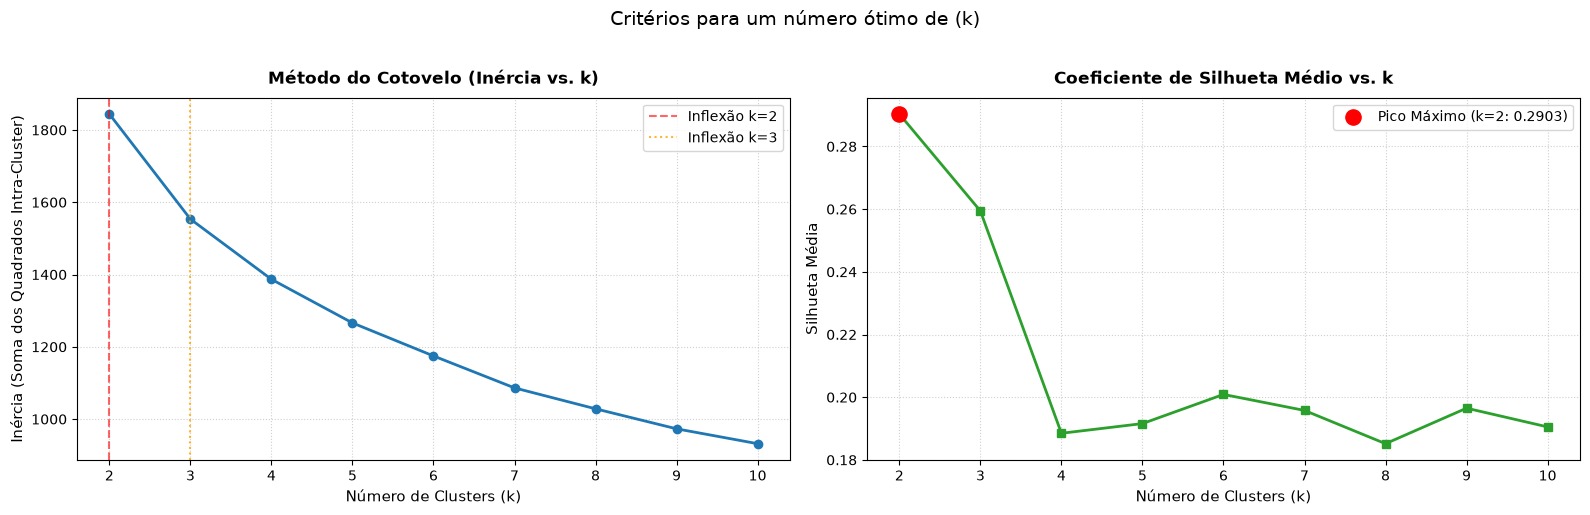

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# método do Cotovelo (Inércia)
axes[0].plot(k_valores, inercias, marker='o', linewidth=2, color='#1f77b4')
axes[0].set_title('Método do Cotovelo (Inércia vs. k)', fontsize=12, pad=10, fontweight='bold')
axes[0].set_xlabel('Número de Clusters (k)', fontsize=11)
axes[0].set_ylabel('Inércia (Soma dos Quadrados Intra-Cluster)', fontsize=11)
axes[0].set_xticks(k_valores)
axes[0].grid(True, linestyle=':', alpha=0.6)

# destacando o ponto de inflexão em k=2 / k=3
axes[0].axvline(x=2, color='red', linestyle='--', alpha=0.6, label='Inflexão k=2')
axes[0].axvline(x=3, color='orange', linestyle=':', alpha=0.8, label='Inflexão k=3')
axes[0].legend()

# coeficiente de Silhueta Médio
axes[1].plot(k_valores, silhuetas, marker='s', linewidth=2, color='#2ca02c')
axes[1].set_title('Coeficiente de Silhueta Médio vs. k', fontsize=12, pad=10, fontweight='bold')
axes[1].set_xlabel('Número de Clusters (k)', fontsize=11)
axes[1].set_ylabel('Silhueta Média', fontsize=11)
axes[1].set_xticks(k_valores)
axes[1].grid(True, linestyle=':', alpha=0.6)

# marcando o pico da silhueta
melhor_k_sil = k_valores[np.argmax(silhuetas)]
axes[1].scatter(melhor_k_sil, max(silhuetas), color='red', s=120, zorder=5, label=f'Pico Máximo (k={melhor_k_sil}: {max(silhuetas):.4f})')
axes[1].legend()

plt.suptitle('Critérios para um número ótimo de (k)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

- **Por que a inércia decresce monotonicamente com k ?**

Podemos perceber com o gráfico de inércia pelo número de clusters k que a inércia sempre irá cair de forma monotonica. Isso acontece pois **a inércia representa o quão próximos e compactos as amostras que estão dentro do clusters estão por meio da distância até o centroide**. 

Consequentemente, a medida que a quantidade de clusters aumenta, haverão mais pontos de referência para serem alocados os centroides dos novos clusters e, dessa forma, **sempre resultará no calculo de distâncias menores**, pois agora com a presença de novos centroides, as distâncias entre as amostras e os centróides serão inevitávelmente menores, diminuindo inevitávelmente a inércia. 

--- 

Sabemos que a inércia mede a soma dos quadrados das distâncias de cada amostra $x_i$ ao centróide $c_k$ do cluster a que foi atribuída:

$$\text{Inércia} = \sum_{i=1}^{n} \min_{c_k} \| x_i - c_k \|^2$$

A cada novo centróide adicionado ao modelo (k + 1), ele necessariamente é alocado mais próximo de algum conjunto de pontos (ou, na pior das hipóteses, na mesma posição). Portanto, a distância de cada ponto ao seu centro mais próximo **ou diminui, ou permanece inalterada**, tornando matematicamente impossível a inércia aumentar com o acréscimo de k.

- **O que ocorre no caso limite em que k é igual ao número de amostras ?**

Isso significa que cada cluster terá exatamente 1 única amostra e o centroide estará logo em cima dessa amostra. Consequentemente, a distância irá zerar e, portanto, a inércia será zero. 

- **Por que a inércia não pode ser usada isoladamente ?**

Caso a inércia fosse o único critério de decisão, o algoritmo sempre preferiria o maior k possível, pois a inércia sempre diminui conforme k cresce. Contudo, à medida que continua aumentando a quantidade de clusters k além do necessário, o  k-means começa a "fatiar" grupos que naturalmente deveriam estar juntos. Isso faz com que o coeficiente de silhueta diminua consideravelmente e o modelo acaba decorando a posição exata das amostras do conjunto de dados de treino, gerando o overfitting.


Por isso, é necessário buscar o ponto de inflexão (cotovelo) que representa o ponto com o melhor valor de k e, para isso, não basta apenas utilizar o valor da inércia como base mas também combinar com métricas que penalizem o excesso de clusters, como a Silhueta. Porque **enquanto você observa a inércia caindo a medida que a quantidade de clusters k vai aumentando, também é necessário observar o critério de silhueta para saber se você não está exagerando com a quantidade de clusters que estão sendo formadas**.

- **Escolhendo o valor do k**

A partir do método do cotovelo será possível determinar a partir de qual k acrescentar o grupo deixaria o ganho significativo. É basicamente o ponto onde a curva da inércia deixa de cair tão rapidamente. Além disso, se o valor maior do score de silhueta também coincidir com um valor de k onde o método do cotovelo aponta ser o melhor caso, isso acaba se tornando mais uma justificativa forte para escolher o valor k em específico. 

Dito isso, o valor k escolhido foi `k = 2`.


## 4. Inicialização e convergência: o 𝑘-Means converge para um mı́nimo local, e não necessariamente global. Execute o algoritmo dez vezes com init=’random’ e n init=1, usando sementes distintas, e registre a inércia final de cada execução. Repita o procedimento com init=’k-means++’. Compare a dispersão dos resultados nos dois casos e explique qual problema a inicialização k-means++ busca mitigar e de que forma.

Sabemos que o k-means converge para um mínimo local que nem sempre é um mínimo global. Isso vai ser testado executando o algoritmo 10 vezes com `init= 'random'` e `n_init= 1`, usando seeds distintas e registrando as inércias de cada execução. 

Será possível fazer a comparação  explicando qual problema a inicialização k-means++ busca mitigar (e de que forma), com relação à inicializações randômicas. 


In [27]:
k_escolhido = 2
# seeds aleatórias para a execução do valor de execução inicial 10 vezes
sementes = [10, 20, 30, 42, 55, 67, 84, 99, 123, 2024]

inercias_random = []
inercias_kmeans_plus = []

# executando o modelo k-means 10x
for seed in sementes:
    # inicialização randômica
    km_rnd = KMeans(n_clusters= k_escolhido, init='random', n_init=1, random_state= seed)
    km_rnd.fit(X_scaled)
    inercias_random.append(km_rnd.inertia_)

    # inicialização inteligente (k-means++)
    km_plus = KMeans(n_clusters=k_escolhido, init='k-means++', n_init=1, random_state=seed)
    km_plus.fit(X_scaled)
    inercias_kmeans_plus.append(km_plus.inertia_)


In [28]:
# tabela com os resultados de cada uma das 10 execuções
df_convergencia = pd.DataFrame({
    'Execução': range(1, 11),
    'Semente (seed)': sementes,
    'Inércia (random)': inercias_random,
    'Inércia (k-means++)': inercias_kmeans_plus,
    'Diferença (Random - Plus)': np.array(inercias_random) - np.array(inercias_kmeans_plus)
})
print("--- Comparativo das 10 Execuções (n_init = 1) ---")
display(df_convergencia.round(4))

--- Comparativo das 10 Execuções (n_init = 1) ---


,Execução,Semente (seed),Inércia (random),Inércia (k-means++),Diferença (Random - Plus)
0,1,10,1844.0641,1844.0641,0.000
1,2,20,1844.0641,1844.0641,0.000
2,3,30,1844.0641,1844.1270,-0.063
3,4,42,1844.1270,1844.1270,0.000
4,5,55,1844.1270,1844.1270,0.000
5,6,67,1844.0641,1844.0641,0.000
6,7,84,1844.0641,1844.1270,-0.063
7,8,99,1844.0641,1844.0641,0.000
8,9,123,1844.0641,1844.0641,0.000
9,10,2024,1844.0641,1844.1270,-0.063


In [29]:
# tabela das estatisticas
df_dispersao = pd.DataFrame({
    'Métrica': ['Mínimo (Melhor Inércia)', 'Média', 'Máximo (Pior Inércia)', 'Desvio Padrão', 'Amplitude (Max - Min)'],
    'init="random"': [
        np.min(inercias_random),
        np.mean(inercias_random),
        np.max(inercias_random),
        np.std(inercias_random),
        np.max(inercias_random) - np.min(inercias_random)
    ],
    'init="k-means++"': [
        np.min(inercias_kmeans_plus),
        np.mean(inercias_kmeans_plus),
        np.max(inercias_kmeans_plus),
        np.std(inercias_kmeans_plus),
        np.max(inercias_kmeans_plus) - np.min(inercias_kmeans_plus)
    ]
})
print("\n--- Estatísticas de Dispersão e Estabilidade ---")
display(df_dispersao.round(4))


--- Estatísticas de Dispersão e Estabilidade ---


,Métrica,"init=""random""","init=""k-means++"""
0,Mínimo (Melhor Inércia),1844.0641,1844.0641
1,Média,1844.0767,1844.0955
2,Máximo (Pior Inércia),1844.1270,1844.1270
3,Desvio Padrão,0.0252,0.0315
4,Amplitude (Max - Min),0.0630,0.0630


- **Por que o k-means converge para um mínimo local e não necessariamente um mínimo global ?**

O algoritmo de Lloyd é o algoritmo responsável pelo método de implementação dos centroides. É a partir dele que é possível implementar o mecanismo de agrupamento do k-means, realizando iterações onde:

```
fixa os centroides -> otimiza atribuições
fixa atribuições -> otimiza os centroides
repete até convergir
```

1. Atribui a cada ponto ao centroide mais próximo
2. Recalcula o centroide como a média dos pontos atribuitos

A função de vai buscar a redução da inércia e não do erro, como é visto em problemas de aprendizagem supervisionado. 

- **O problema da inicialização aleatória (`init= 'random'`)**

Pelo fato de inicializarmos o algoritmo de forma aleatória e nisso, existe a chance de que dois centróides comecem juntos ou muito próximos de si dentro do mesmo grupo denso de pontos. Consequentemente, eles acabam fatiando um agrupamento natural ao meio, enquanto outros aglomerados distantes podem ficar sem nenhum centróide por perto. 

Dessa forma, como os centroides foram inicializados de forma aleatória e algumas amostras ficaram distantes desses centróides devido à má-distribuição deles, isso impacta diretamente no aumento da inércia (o que é ruim para constar o modelo como um bom agrupamento).

Além disso, **os centróides próximos favorecem com que o algoritmo caia na armadilha dos mínimos locais** pois além deles ficarem presos como âncoras na região (puxados para o centro da massa amostral), os centroides próximos racham a multidão ao meio. Logo, se o centroide A e o centroide B racham o cluster C, a inércia dos centroides A e B nunca chegaram em um mínimo global pois o agrupamento natural de C está dividido entre dois centroides. 

- **Como a inicialização usando `k-means++` busca mitigar esse problema e de que forma ?**

Ao invés de sortear a posição inicial dos centróides de forma aleatória utilizando `init= 'random'`, o `k-means++` é aplicado justamente com o objetivo de espalhar a posição inicial dos centróides de forma inteligente. Ele faz isso da seguinte forma:

1. Ele sorteia a posição do primeiro centroide de forma aleatória entre todas as amostras
2. Para cada ponto restante $x_i$, ele calcula a distância $D(x_i)$ até o centróide mais próximo já selecionado 
3. O próximo centróide é sorteado de forma ponderada (agora possui um peso), pois ele é sorteado com probabilidade proporcional ao quadrado da distância

$$P(x) = \frac{D(x)^2}{\sum_{j=1}^{n} D(x_j)^2}$$

4. Esse processo é repetido até que todos os k centroides sejam alocados

Dessa forma, o `k-means++` força a posição dos centróides iniciais a começarem bem espalhados e distantes uns dos outros, reduzindo de forma significativa a chance de cair em mínimos locais ruins e garantindo uma inércia consistentemente menor desde o começo.


## 5. Interpretação e validação dos grupos: com o 𝑘 escolhido, recupere os centróides, reverta-os para a escala original de gasto (desfazendo a padronização e a transformação logarı́tmica) e apresente-os em uma tabela e em um gráfico de barras agrupadas por categoria. Atribua a cada agrupamento um nome descritivo de natureza comercial, baseado nas categorias em que ele se destaca. Em seguida, realize uma validação externa: construa tabelas de contingência cruzando o agrupamento de cada cliente com Channel e com Region, e calcule o ı́ndice Rand ajustado (Adjusted Rand Index) entre a partição obtida e a variável Channel. Responda: o algoritmo, sem jamais ter visto o canal de venda, foi capaz de reconstruı́-lo? Qual conjunto de categorias de produto mais separa Horeca de Retail? E a região geográfica — ela se reflete nos agrupamentos? Por fim, projete os dados em duas dimensões por PCA, colorindo os pontos por agrupamento, e discuta duas limitações do 𝑘-Means evidenciadas nesse gráfico: a tendência a formar grupos de geometria esférica e de tamanhos semelhantes e a sensibilidade a outliers.

O modelo do k-means final será treinado com o k escolhido = 2. 


Em seguida, iremos recuperar os centroides: 

1. desfazendo a normalização z-score usando `scaler.inverse_transform()` 
2. desfazendo a transformação log(1 + x) aplicando euler para cancelar o log usando  `expm1()`

Depois disso, foi possível criar um df que registrasse os centroides na escala monetária real e plotar um gráfico de barras agrupado por categoria.

In [30]:

# treinando o modelo final com k = 2, para pegar os centroides
kmeans_final = KMeans(n_clusters=2, init='k-means++', n_init=10, random_state=42)
df['Cluster'] = kmeans_final.fit_predict(X_scaled)

# desfazendo o z-score
centros_log = scaler.inverse_transform(kmeans_final.cluster_centers_)

# log(1 + x) -> exp(x) - 1
centros_originais = np.expm1(centros_log)

# criando df dos centroides revertidos
df_centroides = pd.DataFrame(
    centros_originais, 
    columns=gastos_cols, 
    index=['Cluster 0 (Horeca / Alimentação)', 'Cluster 1 (Varejo / Mercados)']
)

print("--- Gastos Típicos dos Centróides na Escala Original (Unidades Monetárias) ---")
display(df_centroides.round(2))

--- Gastos Típicos dos Centróides na Escala Original (Unidades Monetárias) ---


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster 0 (Horeca / Alimentação),8580.59,1753.70,2274.38,2063.83,287.37,649.35
Cluster 1 (Varejo / Mercados),4013.88,8061.57,12051.07,953.53,4035.60,1022.09



Distribuição dos Clientes: Cluster 0 = 252 clientes | Cluster 1 = 188 clientes



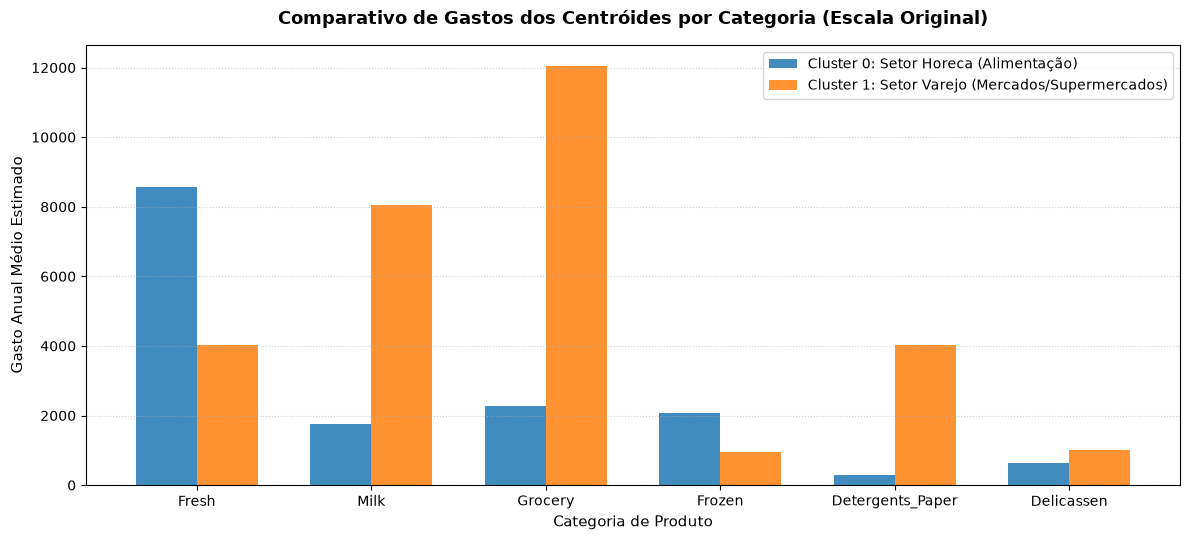

In [ ]:
# Contagem de clientes por cluster
contagem_clusters = df['Cluster'].value_counts().sort_index()
print(f"\nDistribuição dos Clientes: Cluster 0 = {contagem_clusters[0]} clientes | Cluster 1 = {contagem_clusters[1]} clientes\n")

# grafico de barras agrupadas dos centróides por categoria
x = np.arange(len(gastos_cols))
largura = 0.35

plt.figure(figsize=(12, 5.5))
plt.bar(x - largura/2, df_centroides.iloc[0], largura, label='Cluster 0: Setor Horeca (Alimentação)', color='#1f77b4', alpha=0.85)
plt.bar(x + largura/2, df_centroides.iloc[1], largura, label='Cluster 1: Setor Varejo (Mercados/Supermercados)', color='#ff7f0e', alpha=0.85)

plt.title('Comparativo de Gastos dos Centróides por Categoria (Escala Original)', fontsize=13, pad=15, fontweight='bold')
plt.xlabel('Categoria de Produto', fontsize=11)
plt.ylabel('Gasto Anual Médio Estimado', fontsize=11)
plt.xticks(x, gastos_cols, fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

- **Validação Externa**: 

Foram construídas as tabelas de contingência cruzando o agrupamento de cada cliente com `Channel` e com `Region`. Para isso, foi necessário inicialmente mapear os nomes originais que precisariam ser descritos de acordo com o enunciado.

> Channel: 1 = Horeca (Hotéis, Restaurantes, Cafés) / 2 = Retail (Varejo)
> Region: 1 = Lisboa, 2 = Porto, 3 = Outras Regiões

Dessa forma, será possível criar a tabela de contingência de `Channel`: (cluster x canal de venda) e também a tabela de contingência de `Region`: (cluster x região geográfica) e no final, calcular o ı́ndice Rand ajustado (ARI - Adjusted Rand Index) entre a partição obtida e para as features de `Channel` e `Region`. 


In [ ]:
from sklearn.metrics import adjusted_rand_score

# mapeando os nomes originais descritos no enunciado
df['Channel_Nome'] = df['Channel'].map({1: 'Horeca (Hotel/Rest/Café)', 2: 'Retail (Varejo)'})
df['Region_Nome'] = df['Region'].map({1: 'Lisboa', 2: 'Porto', 3: 'Outras Regiões'})

# Cluster vs Channel
print("--- Tabela de Contingência: Cluster vs. Canal de Venda (Channel) ---")
ct_channel = pd.crosstab(df['Cluster'], df['Channel_Nome'], margins=True, margins_name="Total")
display(ct_channel)

# Cluster vs Region
print("\n--- Tabela de Contingência: Cluster vs. Região Geográfica (Region) ---")
ct_region = pd.crosstab(df['Cluster'], df['Region_Nome'], margins=True, margins_name="Total")
display(ct_region)

# Indice Rand Ajustado (ARI)
ari_channel = adjusted_rand_score(df['Channel'], df['Cluster'])
ari_region = adjusted_rand_score(df['Region'], df['Cluster'])

print("\n--- Métricas de Validação Externa (Adjusted Rand Index) ---")
print(f"ARI (Cluster vs. Channel): {ari_channel:.4f} ({ari_channel*100:.2f}%)")
print(f"ARI (Cluster vs. Region):  {ari_region:.4f} ({ari_region*100:.2f}%)")

--- Tabela de Contingência: Cluster vs. Canal de Venda (Channel) ---


Channel_Nome,Horeca (Hotel/Rest/Café),Retail (Varejo),Total
Cluster,,,
0,244,8,252
1,54,134,188
Total,298,142,440



--- Tabela de Contingência: Cluster vs. Região Geográfica (Region) ---


Region_Nome,Lisboa,Outras Regiões,Porto,Total
Cluster,,,,
0,48,176,28,252
1,29,140,19,188
Total,77,316,47,440



--- Métricas de Validação Externa (Adjusted Rand Index) ---
ARI (Cluster vs. Channel): 0.5135 (51.35%)
ARI (Cluster vs. Region):  -0.0077 (-0.77%)


- **O algoritmo, sem jamais ter visto o canal de venda `Channel`, foi capaz de reconstruı́-lo ?**

Sim, é possível interpretar que o algoritmo foi capaz de reconstruir o canal de venda por duas coisas:

1. **Os clusters conseguiram capturar uma quantidade significativa de amostras:**

Mesmo sendo um algoritmo de aprendizado não supervisionado que nunca teve a feature `Channel`, a tabela de contingência mostra que o cluster 0 capturou 244 das 298 amostras de Horeca. Já o cluster 1 capturou 134 dos 142 clientes varejistas (de `Retail`).

2. **O ARI (Adjusted Rand Index) comprova isso:**

O valor de ARI de 0,5135 (51,35%) demonstra que há uma forte concordância entre a partição descoberta e a realidade comercial, pois um ARI acima de 50% já é considerado como um alinhamento expressivo.

- **Qual conjunto de categorias de produto mais separa Horeca de Retail? E a região geográfica — ela se reflete nos agrupamentos ?**


O par de conjuntos que mais separa os dois canais é **`Grocery` + `Detergents_Paper` X `Fresh` + `Frozen`**:

1. **O Canal Varejo (Cluster 1)** apresenta gastos grandes em produtos não perecíveis de prateleira: `Grocery` ($12.051$ vs $2.274$) e `Detergents_Paper` ($4.035$ vs $287$, sendo **14 vezes maior** que no Cluster 0).

2. **O Canal Horeca (Cluster 0)** é focado essencialmente no preparo de refeições no local, comprando muito mais produtos perecíveis: `Fresh` ($8.580$ vs $4.013$) e `Frozen` ($2.063$ vs $953$, mais que o dobro).

- **A região geográfica `Region` se reflete nos agrupamentos ?**

Não, e isso é comprovado também pela métrica do ARI entre os clusters e a feature `Region` foi praticamente 0 (-0,77%), isso indica que os agrupamentos foram feitos praticamente de forma aleatória. 

O cenário ruim fica mais comprovado ainda quando analisamos a distribuição dos clientes entre o cluster 0 e 1 em Lisboa, no Porto ou em outras regiões e constatamos que é praticamente idêntica à média global (aproximadamente 57% do cluster 0 e 43% do cluster 1 em todas as regiões)

---

E por fim, fazemos a projeção bidimensional dos clusters por meio do PCA.


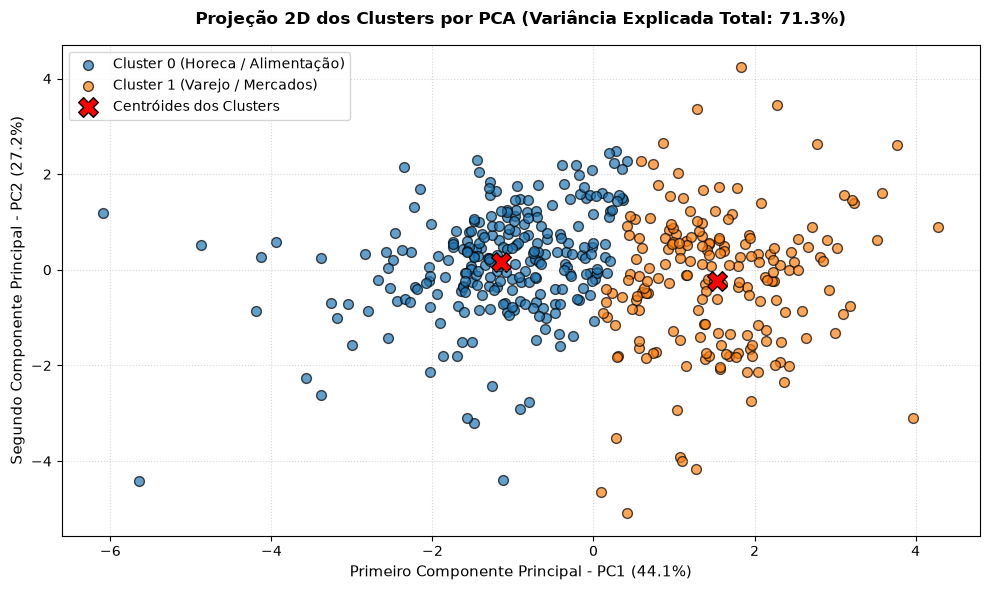

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

# plotando o gráfico
plt.figure(figsize=(10, 6))

cores = ['#1f77b4', '#ff7f0e']
rotulos_legenda = ['Cluster 0 (Horeca / Alimentação)', 'Cluster 1 (Varejo / Mercados)']

for i in range(2):
    plt.scatter(
        X_pca[df['Cluster'] == i, 0], 
        X_pca[df['Cluster'] == i, 1],
        c=cores[i], 
        label=rotulos_legenda[i],
        alpha=0.7, 
        edgecolors='k', 
        s=50
    )

# centróides projetados no espaço do PCA
centros_pca = pca.transform(kmeans_final.cluster_centers_)
plt.scatter(centros_pca[:, 0], centros_pca[:, 1], c='red', marker='X', s=200, label='Centróides dos Clusters', edgecolor='black')

plt.title(f'Projeção 2D dos Clusters por PCA (Variância Explicada Total: {var_pc1 + var_pc2:.1f}%)', fontsize=12, pad=15, fontweight='bold')
plt.xlabel(f'Primeiro Componente Principal - PC1 ({var_pc1:.1f}%)', fontsize=11)
plt.ylabel(f'Segundo Componente Principal - PC2 ({var_pc2:.1f}%)', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


A partir do gráfico, é possível observar duas limitações existentes no algoritmo do k-means:

- **A tendência a formar grupos de geometria esférica e de tamanhos semelhantes**

O k-means utiliza a distância euclidiana por padrão e isso assume implicitamente que os clusters são hiper-esferas isotrópicas de dispersão similar. Logo, a fronteira de decisão gerada é sempre uma linha reta / hiperplano linear perpendicular que divide o espaço.

A nuvem real de dados forma uma massa contínua e alongada, sem uma separação vazia no meio. O k-means impõe um corte de segmentação reto bem no centro da dispersão, forçando uma divisão geométrica rígida que não respeita a curvatura natural dos dados e acaba tentando manter grupos de tamanhos equilibrados (252 vs 188 clientes).

- **Sensibilidade a outliers**

A função de perda da inércia irá minimizar a soma das distâncias ao quadrado. Por causa desse expoente quadrático, pontos distantes geram erros desproporcionalmente gigantescos.

A questão é que mesmo após o logaritmo e o Z-score, existem alguns clientes atípicos isolados nas bordas do gráfico, como podemos visualizar. Esses pontos extremos exercem um "efeito de alavancagem", puxando a posição do centróide em direção a eles e afastando-o do centro da maior concentração de clientes.
